In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [70]:
try:
    df = pd.read_csv("sales_data.csv")

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

except FileNotFoundError:
    print("Error: sales_data.csv file not found.")

Dataset loaded successfully!
Dataset shape: (100, 7)


In [71]:
display(df.head())

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [72]:
print("Dataset Information")
print("-" * 40)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information
----------------------------------------
Rows: 100
Columns: 7

Column Names:
['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']

Data Types:
Date           object
Product        object
Quantity        int64
Price           int64
Customer_ID    object
Region         object
Total_Sales     int64
dtype: object

Missing Values:
Date           0
Product        0
Quantity       0
Price          0
Customer_ID    0
Region         0
Total_Sales    0
dtype: int64


In [73]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("Updated column names:")
print(df.columns.tolist())

Updated column names:
['date', 'product', 'quantity', 'price', 'customer_id', 'region', 'total_sales']


In [74]:
os.makedirs("visualizations", exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


In [75]:
sns.set_theme(
    style="whitegrid",
    palette="deep",
    font_scale=1.1
)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 12

print("Visualization theme configured!")

Visualization theme configured!


In [76]:
print(df.columns.tolist())

['date', 'product', 'quantity', 'price', 'customer_id', 'region', 'total_sales']


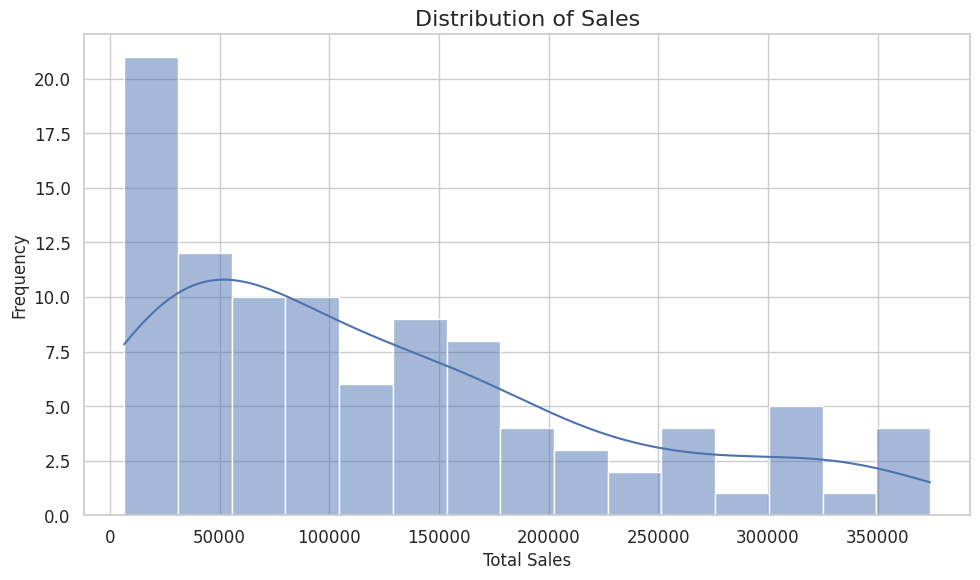

In [77]:
if "total_sales" in df.columns:

    plt.figure(figsize=(10, 6))

    sns.histplot(
        data=df,
        x="total_sales",
        bins=15,
        kde=True
    )

    plt.title("Distribution of Sales")
    plt.xlabel("Total Sales")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.savefig(
        "visualizations/sales_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Please identify the correct sales column first.")

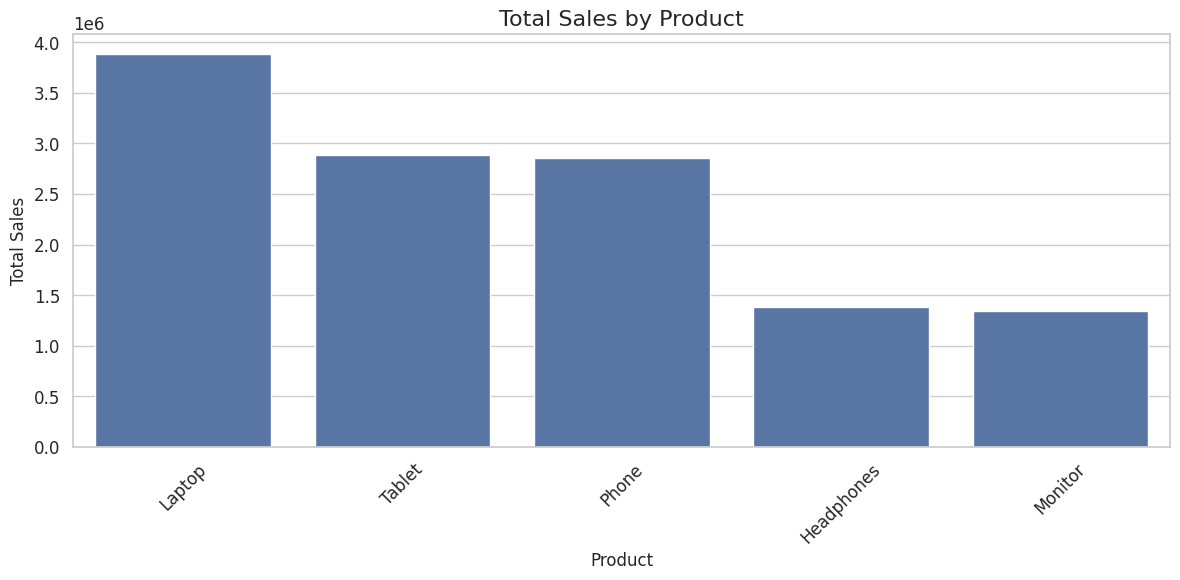

In [78]:
if {"product", "total_sales"}.issubset(df.columns):

    product_sales = (
        df.groupby("product")["total_sales"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=product_sales.index,
        y=product_sales.values
    )

    plt.title("Total Sales by Product")
    plt.xlabel("Product")
    plt.ylabel("Total Sales")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        "visualizations/product_performance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Check whether product and total_sales columns exist.")

In [79]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Shape:", df.shape)

display(df.head())

Dataset Columns:
['date', 'product', 'quantity', 'price', 'customer_id', 'region', 'total_sales']

Dataset Shape: (100, 7)


,date,product,quantity,price,customer_id,region,total_sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [80]:
possible_sales_columns = [
    "total_sales",
    "sales",
    "revenue",
    "amount",
    "price"
]

sales_column = next(
    (col for col in possible_sales_columns if col in df.columns),
    None
)

if sales_column:
    print("Sales column identified:", sales_column)
else:
    print("Sales column not identified.")
    print("Please check the actual column names.")

Sales column identified: total_sales


In [81]:
if sales_column is not None:

    df[sales_column] = pd.to_numeric(
        df[sales_column],
        errors="coerce"
    )

    print("Missing sales values:", df[sales_column].isna().sum())

    print("\nSales data type:")
    print(df[sales_column].dtype)

else:
    print("Cannot proceed without a valid sales column.")

Missing sales values: 0

Sales data type:
int64


In [82]:
if sales_column is not None:

    sales_summary = df[sales_column].describe()

    print("Sales Statistical Summary")
    print("=" * 35)

    display(sales_summary.to_frame(name="Value"))

    print("\nMedian:", df[sales_column].median())
    print("Standard Deviation:", df[sales_column].std())


Sales Statistical Summary


,Value
count,100.000000
mean,123650.480000
std,100161.085275
min,6540.000000
25%,39517.500000
50%,97955.500000
75%,175792.500000
max,373932.000000



Median: 97955.5
Standard Deviation: 100161.08527499213


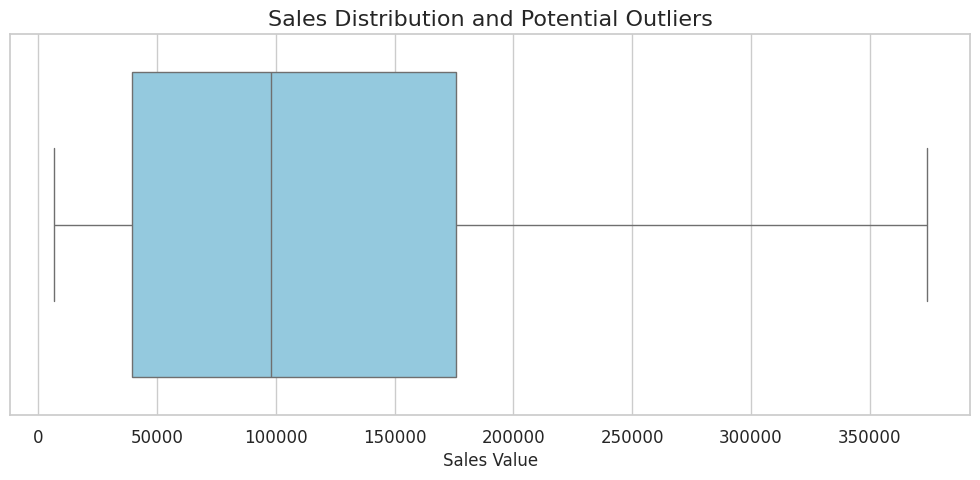

Box plot saved successfully!


In [83]:
if sales_column is not None:

    plot_data = df[sales_column].dropna()

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        x=plot_data,
        color="skyblue"
    )

    plt.title("Sales Distribution and Potential Outliers")
    plt.xlabel("Sales Value")

    plt.tight_layout()

    plt.savefig(
        "visualizations/sales_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Box plot saved successfully!")


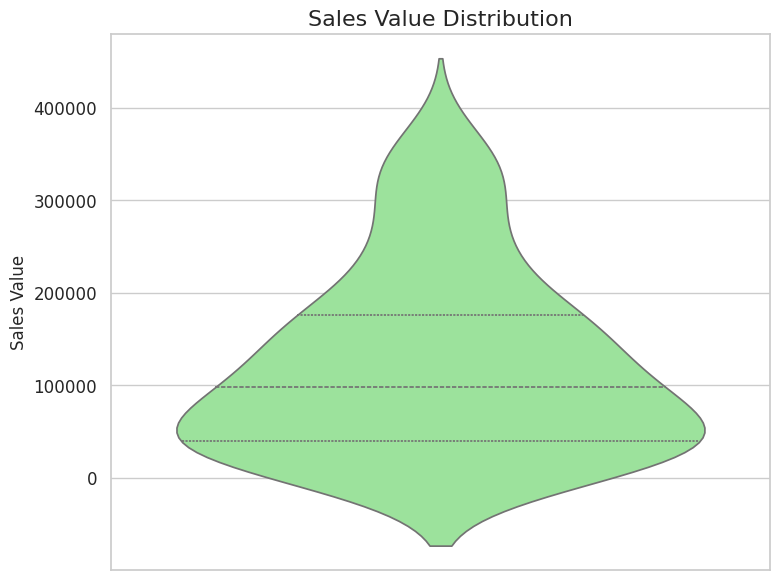

Violin plot saved successfully!


In [84]:
if sales_column is not None:

    plot_data = df[[sales_column]].dropna()

    plt.figure(figsize=(8, 6))

    sns.violinplot(
        data=plot_data,
        y=sales_column,
        color="lightgreen",
        inner="quartile"
    )

    plt.title("Sales Value Distribution")
    plt.ylabel("Sales Value")

    plt.tight_layout()

    plt.savefig(
        "visualizations/sales_violinplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Violin plot saved successfully!")


In [85]:
possible_category_columns = [
    "category",
    "product_category",
    "segment",
    "product"
]

category_column = next(
    (
        col for col in possible_category_columns
        if col in df.columns
    ),
    None
)

if category_column:
    print("Category column identified:", category_column)
    print("\nUnique values:")
    print(df[category_column].nunique())

    display(df[category_column].value_counts().head(10))

else:
    print("No category or product column identified.")
    print("Available columns:", df.columns.tolist())

Category column identified: product

Unique values:
5


,count
product,
Tablet,26
Laptop,24
Phone,20
Headphones,15
Monitor,15


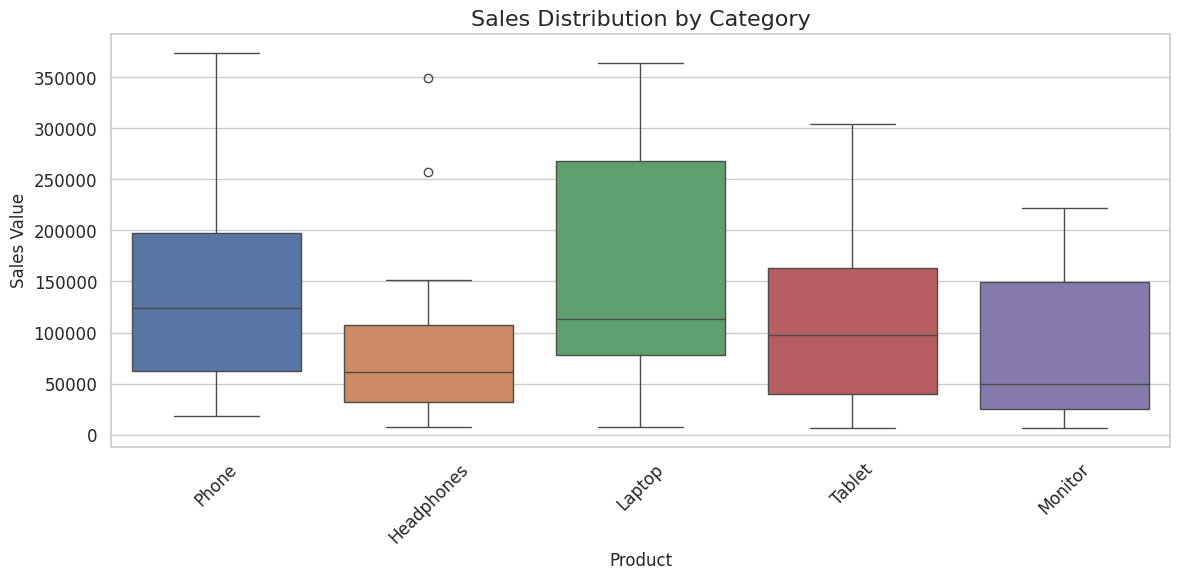

In [86]:
if category_column is not None and sales_column is not None:

    plot_data = df[[category_column, sales_column]].dropna()

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=plot_data,
        x=category_column,
        y=sales_column,
        hue=category_column,
        legend=False
    )

    plt.title("Sales Distribution by Category")
    plt.xlabel(category_column.replace("_", " ").title())
    plt.ylabel("Sales Value")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        "visualizations/category_sales_boxplot.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Category-wise box plot cannot be created.")
    print("Check category and sales column names.")

In [87]:
if sales_column is not None:

    summary_df = df[sales_column].describe().to_frame(
        name="Value"
    )

    summary_df.to_csv(
        "visualizations/sales_statistical_summary.csv"
    )

    print("Statistical summary saved successfully!")

Statistical summary saved successfully!


In [88]:
import os

expected_files = [
    "sales_boxplot.png",
    "sales_violinplot.png",
    "sales_statistical_summary.csv"
]

print("DAY 2 OUTPUT VALIDATION")
print("=" * 40)

for filename in expected_files:

    filepath = os.path.join("visualizations", filename)

    if os.path.exists(filepath):
        print(f"PASS: {filename}")
    else:
        print(f"NOT FOUND: {filename}")

print("\nDay 2 statistical visualization checks completed.")

DAY 2 OUTPUT VALIDATION
PASS: sales_boxplot.png
PASS: sales_violinplot.png
PASS: sales_statistical_summary.csv

Day 2 statistical visualization checks completed.


In [89]:
print("NUMERIC COLUMN ANALYSIS")
print("=" * 40)

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numeric columns:", numeric_columns)
print("Total numeric columns:", len(numeric_columns))

display(df[numeric_columns].head())

NUMERIC COLUMN ANALYSIS
Numeric columns: ['quantity', 'price', 'total_sales']
Total numeric columns: 3


,quantity,price,total_sales
0,7,37300,261100
1,4,15406,61624
2,2,21746,43492
3,1,30895,30895
4,8,39835,318680


In [90]:
print("Missing Values in Numeric Columns")
print("=" * 40)

display(df[numeric_columns].isnull().sum().to_frame(
    name="Missing Values"
))

print("\nNumeric Data Summary:")
display(df[numeric_columns].describe())

Missing Values in Numeric Columns


,Missing Values
quantity,0
price,0
total_sales,0



Numeric Data Summary:


,quantity,price,total_sales
count,100.000000,100.000000,100.000000
mean,4.780000,25808.510000,123650.480000
std,2.588163,13917.630242,100161.085275
min,1.000000,1308.000000,6540.000000
25%,2.750000,14965.250000,39517.500000
50%,5.000000,24192.000000,97955.500000
75%,7.000000,38682.250000,175792.500000
max,9.000000,49930.000000,373932.000000


In [91]:
if len(numeric_columns) >= 2:

    correlation_matrix = df[numeric_columns].corr()

    print("Correlation Matrix")
    display(correlation_matrix.round(2))

else:
    print("At least two numeric columns are required.")

Correlation Matrix


,quantity,price,total_sales
quantity,1.00,0.01,0.69
price,0.01,1.00,0.65
total_sales,0.69,0.65,1.00


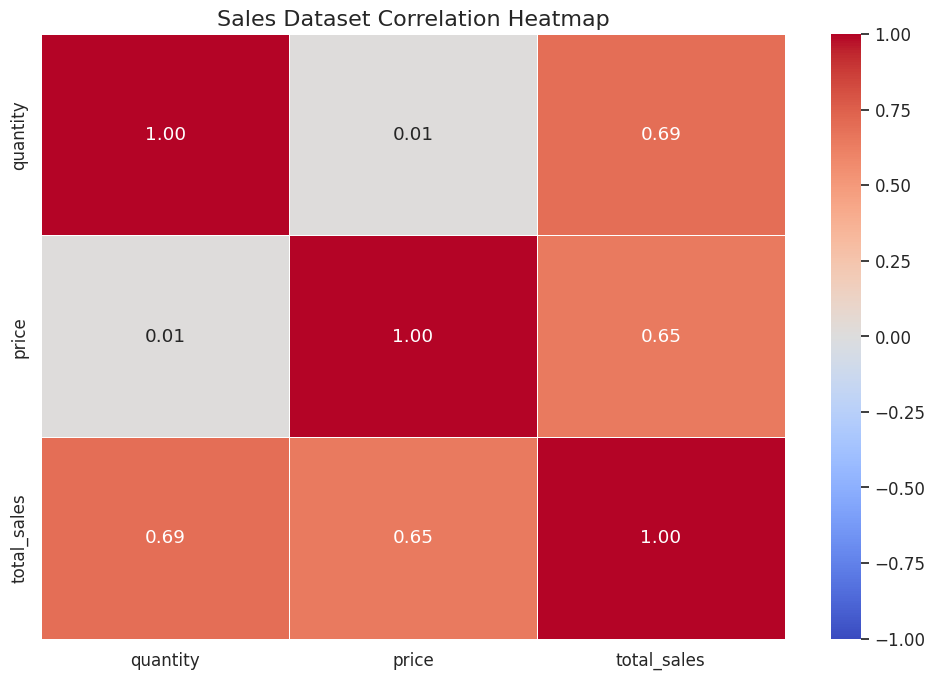

Correlation heatmap saved successfully!


In [92]:
if len(numeric_columns) >= 2:

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        linewidths=0.5,
        vmin=-1,
        vmax=1,
        center=0
    )

    plt.title("Sales Dataset Correlation Heatmap")
    plt.tight_layout()

    plt.savefig(
        "visualizations/correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Correlation heatmap saved successfully!")

else:
    print("Heatmap requires at least two numeric columns.")

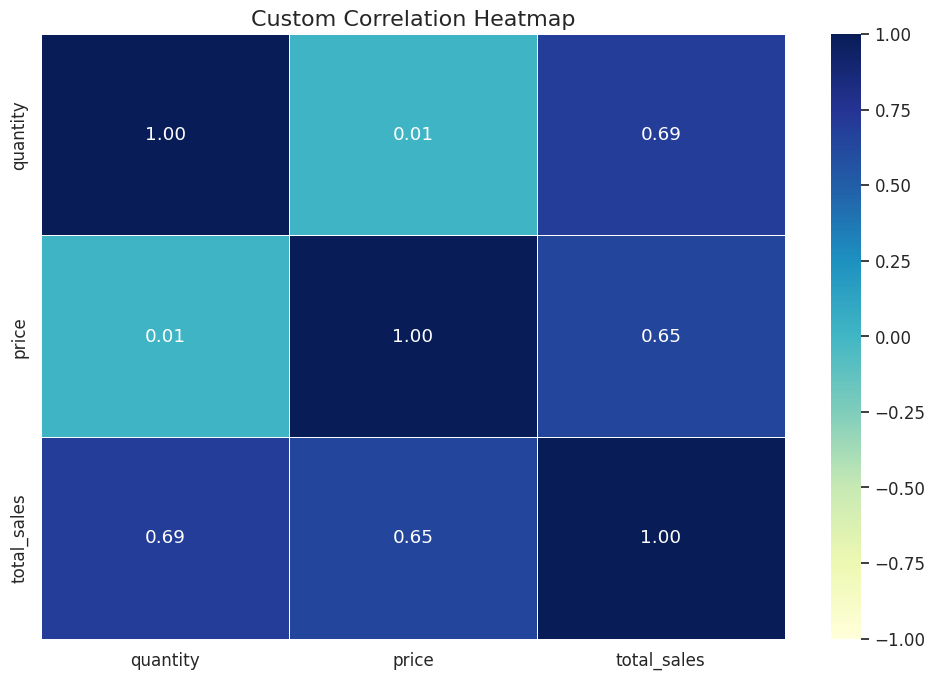

Custom heatmap saved successfully!


In [93]:
if len(numeric_columns) >= 2:

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        linewidths=0.5,
        vmin=-1,
        vmax=1
    )

    plt.title("Custom Correlation Heatmap")
    plt.tight_layout()

    plt.savefig(
        "visualizations/custom_correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Custom heatmap saved successfully!")

In [94]:
if len(numeric_columns) >= 2:

    correlation_pairs = (
        correlation_matrix
        .where(
            np.triu(
                np.ones(correlation_matrix.shape),
                k=1
            ).astype(bool)
        )
        .stack()
        .reset_index()
    )

    correlation_pairs.columns = [
        "Variable 1",
        "Variable 2",
        "Correlation"
    ]

    correlation_pairs["Absolute Correlation"] = (
        correlation_pairs["Correlation"].abs()
    )

    correlation_pairs = correlation_pairs.sort_values(
        "Absolute Correlation",
        ascending=False
    )

    print("Strongest Correlation Pairs")
    display(correlation_pairs.head(10))

else:
    print("Not enough numeric columns for correlation analysis.")

Strongest Correlation Pairs


,Variable 1,Variable 2,Correlation,Absolute Correlation
1,quantity,total_sales,0.688107,0.688107
2,price,total_sales,0.646131,0.646131
0,quantity,price,0.008014,0.008014


In [95]:
if len(numeric_columns) >= 2:

    correlation_matrix.to_csv(
        "visualizations/correlation_matrix.csv"
    )

    correlation_pairs.to_csv(
        "visualizations/correlation_pairs.csv",
        index=False
    )

    print("Correlation matrix saved.")
    print("Correlation pairs saved.")

Correlation matrix saved.
Correlation pairs saved.


In [96]:
import os

expected_files = [
    "correlation_heatmap.png",
    "custom_correlation_heatmap.png",
    "correlation_matrix.csv",
    "correlation_pairs.csv"
]

print("DAY 3 OUTPUT VALIDATION")
print("=" * 40)

for filename in expected_files:

    filepath = os.path.join(
        "visualizations",
        filename
    )

    if os.path.exists(filepath):
        print(f"PASS: {filename}")
    else:
        print(f"NOT FOUND: {filename}")

DAY 3 OUTPUT VALIDATION
PASS: correlation_heatmap.png
PASS: custom_correlation_heatmap.png
PASS: correlation_matrix.csv
PASS: correlation_pairs.csv


In [97]:
print("DAY 4 - DASHBOARD PREPARATION")
print("=" * 45)

print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNumeric columns:", numeric_columns)

print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

DAY 4 - DASHBOARD PREPARATION
Dataset shape: (100, 7)
Available columns: ['date', 'product', 'quantity', 'price', 'customer_id', 'region', 'total_sales']

Numeric columns: ['quantity', 'price', 'total_sales']

Missing values:


,Missing Values
date,0
product,0
quantity,0
price,0
customer_id,0
region,0
total_sales,0


In [98]:
sales_candidates = [
    "total_sales",
    "sales",
    "revenue",
    "amount",
    "price"
]

product_candidates = [
    "product",
    "product_name",
    "item",
    "category",
    "product_category"
]

sales_column = next(
    (col for col in sales_candidates if col in df.columns),
    None
)

product_column = next(
    (col for col in product_candidates if col in df.columns),
    None
)

print("Sales column:", sales_column)
print("Product/category column:", product_column)

Sales column: total_sales
Product/category column: product


In [99]:
numeric_df = df.select_dtypes(
    include=["number"]
)

if numeric_df.shape[1] >= 2:
    correlation_matrix = numeric_df.corr()
    print("Correlation matrix prepared successfully.")

else:
    correlation_matrix = None
    print("At least two numeric columns are required for a heatmap.")

Correlation matrix prepared successfully.


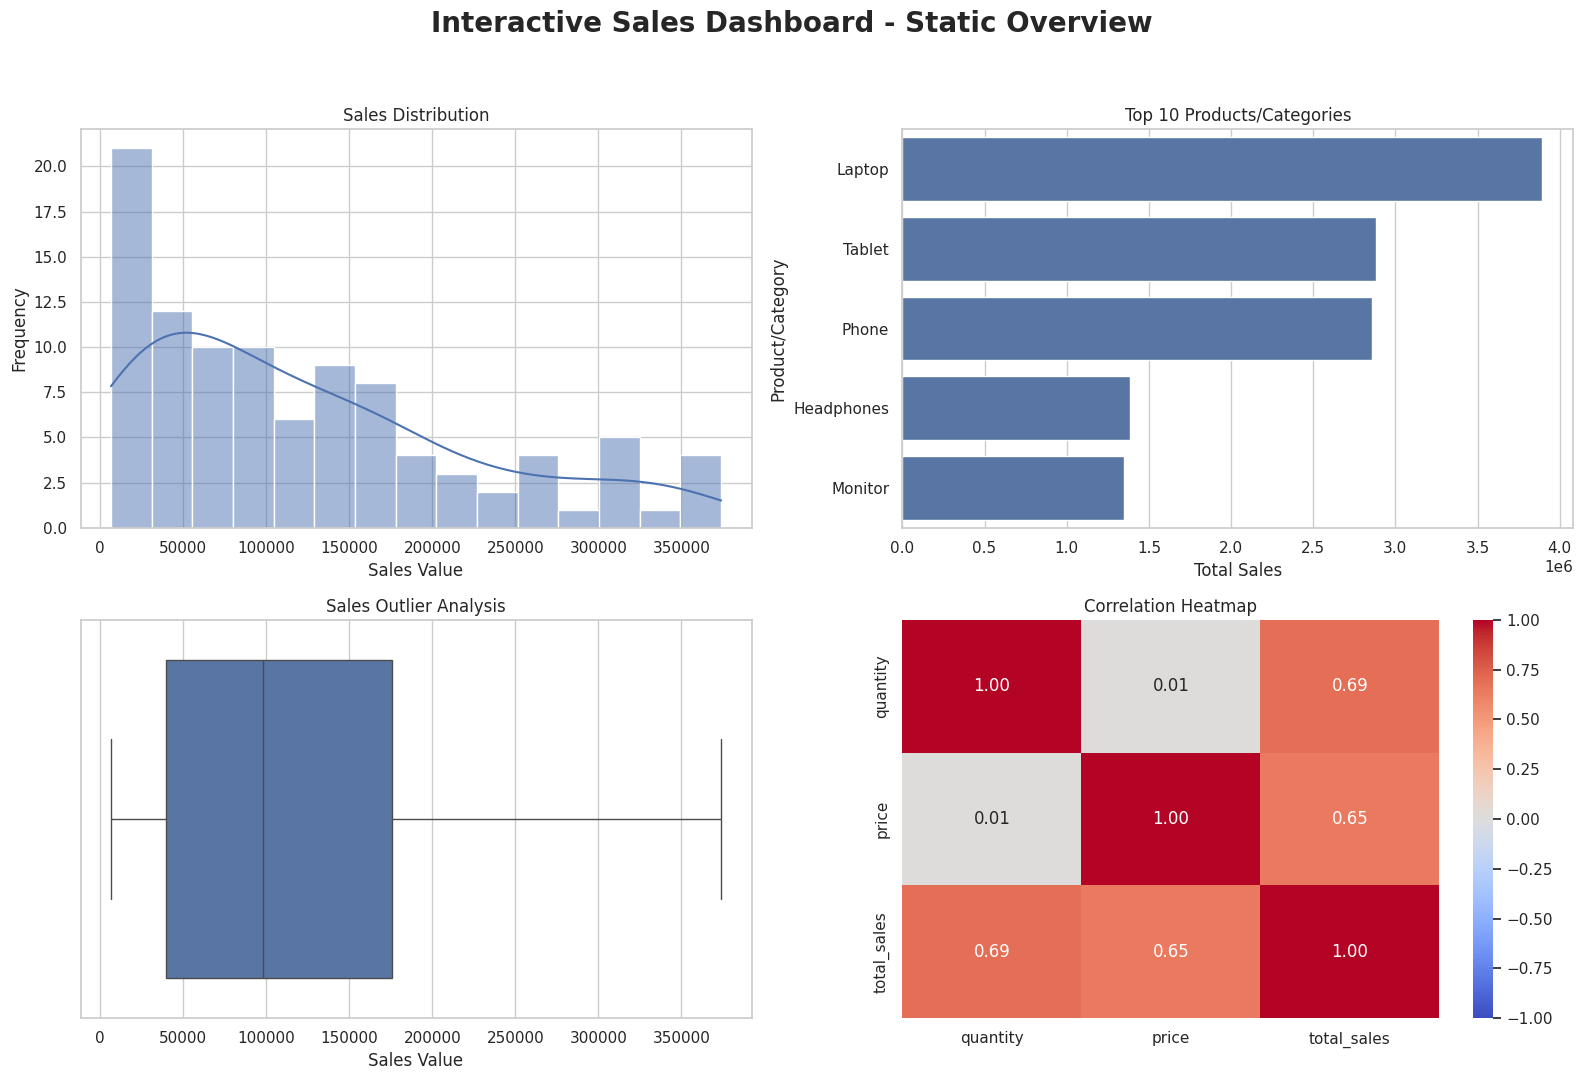

Static dashboard created successfully!


In [100]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

os.makedirs("visualizations", exist_ok=True)

sns.set_theme(
    style="whitegrid",
    palette="deep"
)

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

fig.suptitle(
    "Interactive Sales Dashboard - Static Overview",
    fontsize=20,
    fontweight="bold"
)

# Chart 1: Sales Distribution
if sales_column is not None:

    sales_values = pd.to_numeric(
        df[sales_column],
        errors="coerce"
    ).dropna()

    if not sales_values.empty:
        sns.histplot(
            x=sales_values,
            bins=15,
            kde=True,
            ax=axes[0, 0]
        )

        axes[0, 0].set_title("Sales Distribution")
        axes[0, 0].set_xlabel("Sales Value")
        axes[0, 0].set_ylabel("Frequency")

    else:
        axes[0, 0].text(
            0.5, 0.5, "No valid sales values",
            ha="center", va="center"
        )

else:
    axes[0, 0].text(
        0.5, 0.5, "Sales column not identified",
        ha="center", va="center"
    )

# Chart 2: Product/Category Performance
if sales_column is not None and product_column is not None:

    chart_df = df[[product_column, sales_column]].copy()

    chart_df[sales_column] = pd.to_numeric(
        chart_df[sales_column],
        errors="coerce"
    )

    chart_df = chart_df.dropna()

    product_sales = (
        chart_df.groupby(product_column)[sales_column]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    if not product_sales.empty:
        sns.barplot(
            x=product_sales.values,
            y=product_sales.index,
            ax=axes[0, 1]
        )

        axes[0, 1].set_title("Top 10 Products/Categories")
        axes[0, 1].set_xlabel("Total Sales")
        axes[0, 1].set_ylabel("Product/Category")

    else:
        axes[0, 1].text(
            0.5, 0.5, "No valid product data",
            ha="center", va="center"
        )

else:
    axes[0, 1].text(
        0.5, 0.5, "Product or sales column unavailable",
        ha="center", va="center"
    )

# Chart 3: Sales Box Plot
if sales_column is not None:

    box_values = pd.to_numeric(
        df[sales_column],
        errors="coerce"
    ).dropna()

    if not box_values.empty:
        sns.boxplot(
            x=box_values,
            ax=axes[1, 0]
        )

        axes[1, 0].set_title("Sales Outlier Analysis")
        axes[1, 0].set_xlabel("Sales Value")

    else:
        axes[1, 0].text(
            0.5, 0.5, "No valid sales values",
            ha="center", va="center"
        )

else:
    axes[1, 0].text(
        0.5, 0.5, "Sales column not identified",
        ha="center", va="center"
    )

# Chart 4: Correlation Heatmap
if correlation_matrix is not None:

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        ax=axes[1, 1]
    )

    axes[1, 1].set_title("Correlation Heatmap")

else:
    axes[1, 1].text(
        0.5, 0.5, "Insufficient numeric columns",
        ha="center", va="center"
    )

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "visualizations/static_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Static dashboard created successfully!")

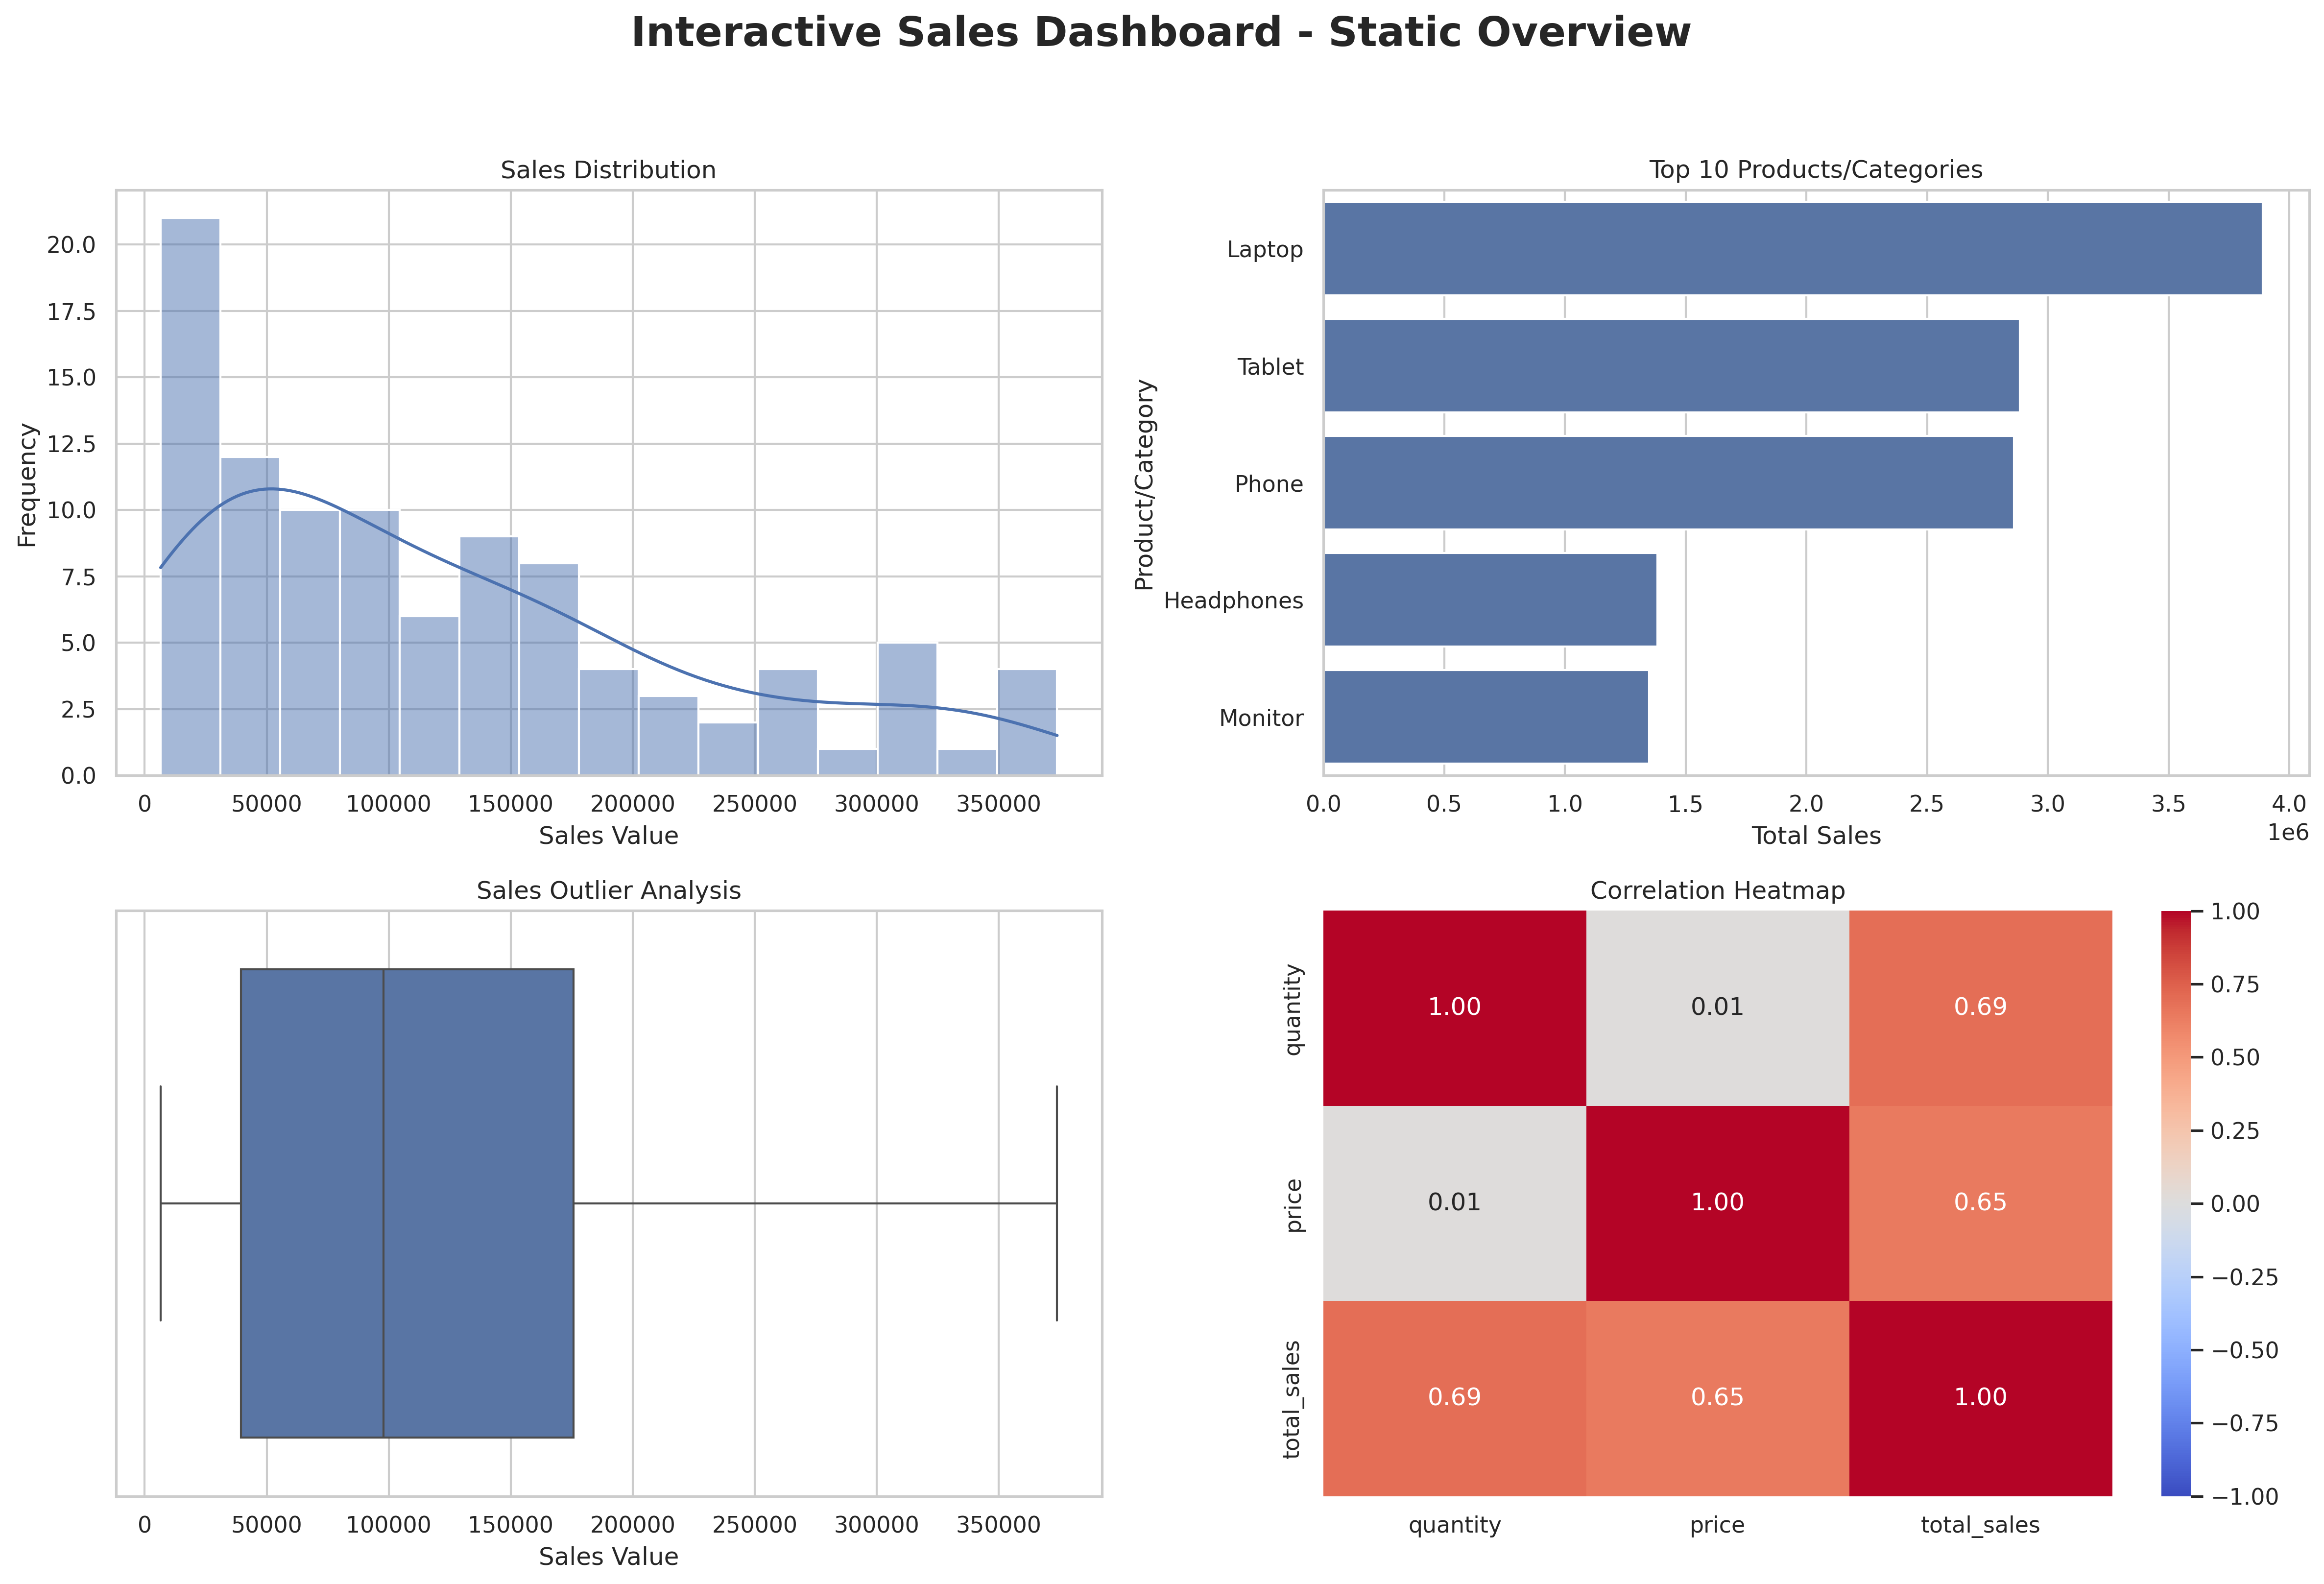

Dashboard image verified successfully.


In [101]:
from IPython.display import Image, display
import os

dashboard_path = "visualizations/static_dashboard.png"

if os.path.exists(dashboard_path):
    display(Image(filename=dashboard_path))
    print("Dashboard image verified successfully.")

else:
    print("Dashboard image not found. Run Cell 32 again.")

In [102]:
import os

required_files = [
    "static_dashboard.png"
]

print("DAY 4 - FINAL VALIDATION")
print("=" * 40)

for filename in required_files:

    path = os.path.join(
        "visualizations",
        filename
    )

    if os.path.exists(path):
        print(f"PASS: {filename}")
    else:
        print(f"FAIL: {filename}")

print("\nDashboard validation completed.")

DAY 4 - FINAL VALIDATION
PASS: static_dashboard.png

Dashboard validation completed.


In [103]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML
import pandas as pd
import numpy as np
import os

os.makedirs("visualizations", exist_ok=True)

print("Plotly libraries imported successfully!")

Plotly libraries imported successfully!


In [104]:
print("Available columns:", df.columns.tolist())

sales_candidates = [
    "total_sales",
    "sales",
    "revenue",
    "amount",
    "price"
]

product_candidates = [
    "product",
    "product_name",
    "item",
    "category",
    "product_category"
]

sales_column = next(
    (col for col in sales_candidates if col in df.columns),
    None
)

product_column = next(
    (col for col in product_candidates if col in df.columns),
    None
)

print("Sales column:", sales_column)
print("Product/category column:", product_column)

Available columns: ['date', 'product', 'quantity', 'price', 'customer_id', 'region', 'total_sales']
Sales column: total_sales
Product/category column: product


In [105]:
if sales_column is not None:

    interactive_df = df.copy()

    interactive_df[sales_column] = pd.to_numeric(
        interactive_df[sales_column],
        errors="coerce"
    )

    interactive_df = interactive_df.dropna(
        subset=[sales_column]
    )

    if product_column is not None:
        interactive_df = interactive_df.dropna(
            subset=[product_column]
        )

    print("Interactive dataset prepared!")
    print("Rows available:", len(interactive_df))

    display(interactive_df.head())

else:
    interactive_df = pd.DataFrame()
    print("Sales column not found. Check the column names.")

Interactive dataset prepared!
Rows available: 100


,date,product,quantity,price,customer_id,region,total_sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [106]:
if (
    not interactive_df.empty
    and product_column is not None
):

    product_sales = (
        interactive_df
        .groupby(product_column, as_index=False)[sales_column]
        .sum()
        .sort_values(sales_column, ascending=False)
    )

    fig = px.bar(
        product_sales,
        x=product_column,
        y=sales_column,
        title="Interactive Product Sales Analysis",
        labels={
            product_column: "Product",
            sales_column: "Total Sales"
        },
        color=sales_column,
        color_continuous_scale="Blues",
        hover_data={sales_column: ":,.2f"}
    )

    fig.update_layout(
        template="plotly_white",
        title_x=0.5,
        xaxis_tickangle=-45,
        height=550
    )

    fig.show()

    fig.write_html(
        "visualizations/interactive_product_sales.html"
    )

    print("Interactive bar chart saved!")

else:
    print("Product sales chart requires valid product and sales columns.")

Interactive bar chart saved!


In [107]:
if not interactive_df.empty:

    fig = px.histogram(
        interactive_df,
        x=sales_column,
        nbins=15,
        marginal="box",
        title="Interactive Sales Distribution",
        labels={
            sales_column: "Sales Value"
        },
        color_discrete_sequence=["#3B82F6"]
    )

    fig.update_layout(
        template="plotly_white",
        title_x=0.5,
        height=550,
        bargap=0.08
    )

    fig.show()

    fig.write_html(
        "visualizations/interactive_sales_distribution.html"
    )

    print("Interactive histogram saved!")

else:
    print("No valid sales data available.")

Interactive histogram saved!


In [108]:
numeric_columns = interactive_df.select_dtypes(
    include=["number"]
).columns.tolist()

other_numeric_columns = [
    col for col in numeric_columns
    if col != sales_column
]

if other_numeric_columns:

    x_column = other_numeric_columns[0]

    fig = px.scatter(
        interactive_df,
        x=x_column,
        y=sales_column,
        hover_data=(
            [product_column]
            if product_column is not None
            else None
        ),
        title=f"{sales_column} vs {x_column}",
        labels={
            x_column: x_column.replace("_", " ").title(),
            sales_column: sales_column.replace("_", " ").title()
        },
        color_discrete_sequence=["#8B5CF6"]
    )

    fig.update_layout(
        template="plotly_white",
        title_x=0.5,
        height=500
    )

    fig.show()

    fig.write_html(
        "visualizations/interactive_scatter_plot.html"
    )

    print("Interactive scatter plot saved!")

else:
    print("A second numeric column is required for a scatter plot.")

Interactive scatter plot saved!


In [109]:
if (
    not interactive_df.empty
    and product_column is not None
):

    product_sales = (
        interactive_df
        .groupby(product_column, as_index=False)[sales_column]
        .sum()
        .sort_values(sales_column, ascending=False)
    )

    fig = go.Figure()

    fig.add_trace(
        go.Bar(
            x=product_sales[product_column],
            y=product_sales[sales_column],
            marker_color="#3B82F6",
            name="Total Sales",
            hovertemplate=(
                "Product: %{x}<br>"
                "Total Sales: %{y:,.2f}"
                "<extra></extra>"
            )
        )
    )

    buttons = [
        dict(
            label="All Products",
            method="update",
            args=[
                {"visible": [True]},
                {"title": "Sales by All Products"}
            ]
        )
    ]

    for _, row in product_sales.iterrows():

        selected_product = row[product_column]

        buttons.append(
            dict(
                label=str(selected_product),
                method="update",
                args=[
                    {
                        "x": [[selected_product]],
                        "y": [[row[sales_column]]],
                        "visible": [True]
                    },
                    {
                        "title": f"Sales for {selected_product}"
                    }
                ]
            )
        )

    fig.update_layout(
        title="Sales by All Products",
        template="plotly_white",
        title_x=0.5,
        height=550,
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                x=1.0,
                y=1.15,
                xanchor="right",
                yanchor="top"
            )
        ],
        xaxis_title="Product",
        yaxis_title="Total Sales"
    )

    fig.show()

    fig.write_html(
        "visualizations/product_dropdown_dashboard.html"
    )

    print("Dropdown dashboard saved successfully!")

else:
    print("Dropdown requires product and sales columns.")

Dropdown dashboard saved successfully!


In [110]:
if not interactive_df.empty:

    total_sales = interactive_df[sales_column].sum()

    average_sales = interactive_df[sales_column].mean()

    highest_sale = interactive_df[sales_column].max()

    total_records = len(interactive_df)

    print("=" * 45)
    print("INTERACTIVE SALES DASHBOARD - SUMMARY")
    print("=" * 45)

    print(f"Total Sales: {total_sales:,.2f}")
    print(f"Average Sales: {average_sales:,.2f}")
    print(f"Highest Sale: {highest_sale:,.2f}")
    print(f"Valid Records: {total_records:,}")

else:
    print("Sales summary unavailable.")

INTERACTIVE SALES DASHBOARD - SUMMARY
Total Sales: 12,365,048.00
Average Sales: 123,650.48
Highest Sale: 373,932.00
Valid Records: 100


In [111]:
import os
from google.colab import files

dashboard_path = "visualizations/product_dropdown_dashboard.html"

if os.path.exists(dashboard_path):
    print("Dashboard file found!")
    files.download(dashboard_path)
else:
    print("Dashboard file not found.")
    print("Please run Cell 40 first.")

Dashboard file found!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [112]:
import os

expected_files = [
    "interactive_product_sales.html",
    "interactive_sales_distribution.html",
    "interactive_scatter_plot.html",
    "product_dropdown_dashboard.html"
]

print("DAY 5 - OUTPUT VALIDATION")
print("=" * 45)

for filename in expected_files:

    filepath = os.path.join(
        "visualizations",
        filename
    )

    if os.path.exists(filepath):
        print(f"PASS: {filename}")
    else:
        print(f"NOT FOUND: {filename}")

print("\nDay 5 validation completed.")

DAY 5 - OUTPUT VALIDATION
PASS: interactive_product_sales.html
PASS: interactive_sales_distribution.html
PASS: interactive_scatter_plot.html
PASS: product_dropdown_dashboard.html

Day 5 validation completed.


In [113]:
import os

print("=" * 55)
print("DAY 6 - DASHBOARD INTEGRATION")
print("=" * 55)

required_files = [
    "visualizations/static_dashboard.png",
    "visualizations/interactive_product_sales.html",
    "visualizations/interactive_sales_distribution.html",
    "visualizations/interactive_scatter_plot.html",
    "visualizations/product_dropdown_dashboard.html"
]

for file_path in required_files:
    if os.path.exists(file_path):
        print(f"✅ Found: {file_path}")
    else:
        print(f"⚠️ Missing: {file_path}")

print("\nDashboard file verification completed.")

DAY 6 - DASHBOARD INTEGRATION
✅ Found: visualizations/static_dashboard.png
✅ Found: visualizations/interactive_product_sales.html
✅ Found: visualizations/interactive_sales_distribution.html
✅ Found: visualizations/interactive_scatter_plot.html
✅ Found: visualizations/product_dropdown_dashboard.html

Dashboard file verification completed.


In [114]:
import os

visualization_folder = "visualizations"

if os.path.exists(visualization_folder):
    dashboard_files = os.listdir(visualization_folder)

    print("Total files in visualizations folder:", len(dashboard_files))
    print("\nAvailable files:")

    for file_name in dashboard_files:
        print("-", file_name)
else:
    print("Visualizations folder not found. Run the earlier dashboard cells.")

Total files in visualizations folder: 15

Available files:
- product_performance.png
- correlation_matrix.csv
- correlation_pairs.csv
- sales_statistical_summary.csv
- interactive_sales_distribution.html
- interactive_product_sales.html
- sales_distribution.png
- correlation_heatmap.png
- sales_boxplot.png
- product_dropdown_dashboard.html
- static_dashboard.png
- category_sales_boxplot.png
- interactive_scatter_plot.html
- custom_correlation_heatmap.png
- sales_violinplot.png


In [115]:
import os

project_summary = {
    "Project": "Interactive Sales Dashboard",
    "Dataset": "sales_data.csv",
    "Tool": "Python - Google Colab",
    "Libraries": "Pandas, Matplotlib, Seaborn, Plotly",
    "Static Dashboard": os.path.exists(
        "visualizations/static_dashboard.png"
    ),
    "Interactive Product Dashboard": os.path.exists(
        "visualizations/product_dropdown_dashboard.html"
    )
}

print("=" * 45)
print("INTERACTIVE SALES DASHBOARD - PROJECT SUMMARY")
print("=" * 45)

for key, value in project_summary.items():
    print(f"{key}: {value}")

INTERACTIVE SALES DASHBOARD - PROJECT SUMMARY
Project: Interactive Sales Dashboard
Dataset: sales_data.csv
Tool: Python - Google Colab
Libraries: Pandas, Matplotlib, Seaborn, Plotly
Static Dashboard: True
Interactive Product Dashboard: True


In [116]:
import os
import pandas as pd

os.makedirs("report", exist_ok=True)

summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=["Project Detail", "Value"]
)

summary_df.to_csv(
    "report/project_summary.csv",
    index=False
)

print("Project summary saved successfully!")
print("File: report/project_summary.csv")

Project summary saved successfully!
File: report/project_summary.csv


In [117]:
import os
import pandas as pd

print("=" * 55)
print("DAY 7 - FINAL PROJECT TESTING")
print("=" * 55)

checks = {
    "Sales Dataset": "sales_data.csv",
    "Static Dashboard": "visualizations/static_dashboard.png",
    "Interactive Product Sales": "visualizations/interactive_product_sales.html",
    "Interactive Sales Distribution": "visualizations/interactive_sales_distribution.html",
    "Interactive Scatter Plot": "visualizations/interactive_scatter_plot.html",
    "Product Dropdown Dashboard": "visualizations/product_dropdown_dashboard.html",
    "Project Summary": "report/project_summary.csv"
}

passed = 0
failed = 0

for name, path in checks.items():
    if os.path.exists(path):
        print(f"PASS: {name}")
        passed += 1
    else:
        print(f"NOT FOUND: {name}")
        failed += 1

print("\n" + "=" * 55)
print("TESTING RESULTS")
print("=" * 55)
print("Passed:", passed)
print("Not found:", failed)
print("Total checks:", len(checks))

DAY 7 - FINAL PROJECT TESTING
PASS: Sales Dataset
PASS: Static Dashboard
PASS: Interactive Product Sales
PASS: Interactive Sales Distribution
PASS: Interactive Scatter Plot
PASS: Product Dropdown Dashboard
PASS: Project Summary

TESTING RESULTS
Passed: 7
Not found: 0
Total checks: 7


In [118]:
import os
from datetime import date

os.makedirs("report", exist_ok=True)

report_content = f"""
# Interactive Sales Dashboard

## 1. Project Overview

This project analyzes sales data and presents the results
through static and interactive visualizations.

## 2. Tools and Technologies

- Python
- Google Colab
- Pandas
- Matplotlib
- Seaborn
- Plotly

## 3. Dataset

Dataset file: sales_data.csv

## 4. Project Work

- Loaded and explored the sales dataset.
- Cleaned column names and prepared data for analysis.
- Created statistical visualizations using Seaborn.
- Examined numerical correlations using a heatmap.
- Built a static dashboard using Matplotlib.
- Created interactive charts using Plotly.
- Prepared a project summary and tested output files.

## 5. Dashboard Files

- static_dashboard.png
- interactive_product_sales.html
- interactive_sales_distribution.html
- interactive_scatter_plot.html
- product_dropdown_dashboard.html

## 6. Conclusion

The project demonstrates how Python visualization libraries
can be used to explore sales data and create interactive
visualizations for understanding sales patterns.

## 7. Environment

Google Colab

## 8. Report Date

{date.today()}
"""

report_path = "report/final_project_report.md"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_content)

print("Final project report created successfully!")
print("Saved at:", report_path)

Final project report created successfully!
Saved at: report/final_project_report.md


In [119]:
from IPython.display import display, Markdown

with open("report/final_project_report.md", "r", encoding="utf-8") as file:
    final_report = file.read()

display(Markdown(final_report))


# Interactive Sales Dashboard

## 1. Project Overview

This project analyzes sales data and presents the results
through static and interactive visualizations.

## 2. Tools and Technologies

- Python
- Google Colab
- Pandas
- Matplotlib
- Seaborn
- Plotly

## 3. Dataset

Dataset file: sales_data.csv

## 4. Project Work

- Loaded and explored the sales dataset.
- Cleaned column names and prepared data for analysis.
- Created statistical visualizations using Seaborn.
- Examined numerical correlations using a heatmap.
- Built a static dashboard using Matplotlib.
- Created interactive charts using Plotly.
- Prepared a project summary and tested output files.

## 5. Dashboard Files

- static_dashboard.png
- interactive_product_sales.html
- interactive_sales_distribution.html
- interactive_scatter_plot.html
- product_dropdown_dashboard.html

## 6. Conclusion

The project demonstrates how Python visualization libraries
can be used to explore sales data and create interactive
visualizations for understanding sales patterns.

## 7. Environment

Google Colab

## 8. Report Date

2026-10-19


In [120]:
import os

print("=" * 50)
print("FINAL PROJECT FILE STRUCTURE")
print("=" * 50)

for folder in ["visualizations", "report"]:
    if os.path.exists(folder):
        print(f"\n📁 {folder}/")

        for file_name in sorted(os.listdir(folder)):
            print("   📄", file_name)

print("\n📄 sales_data.csv")

if os.path.exists("README.md"):
    print("📄 README.md")
else:
    print("README.md not created yet.")

FINAL PROJECT FILE STRUCTURE

📁 visualizations/
   📄 category_sales_boxplot.png
   📄 correlation_heatmap.png
   📄 correlation_matrix.csv
   📄 correlation_pairs.csv
   📄 custom_correlation_heatmap.png
   📄 interactive_product_sales.html
   📄 interactive_sales_distribution.html
   📄 interactive_scatter_plot.html
   📄 product_dropdown_dashboard.html
   📄 product_performance.png
   📄 sales_boxplot.png
   📄 sales_distribution.png
   📄 sales_statistical_summary.csv
   📄 sales_violinplot.png
   📄 static_dashboard.png

📁 report/
   📄 final_project_report.md
   📄 project_summary.csv

📄 sales_data.csv
📄 README.md


In [121]:
readme_content = """
# 📊 Interactive Sales Dashboard

## 👨‍💻 Author

**Nitish Kumar**

B.Tech Computer Science & Engineering Student
Aspiring Data Analyst | Data Science Enthusiast

- **GitHub:** [singhnitish11](https://github.com/singhnitish11)
- **Email:** [nitishsingh1401@gmail.com](mailto:nitishsingh1401@gmail.com)

---

## 📌 Project Overview

The Interactive Sales Dashboard project focuses on analyzing
sales data and presenting useful insights through static and
interactive visualizations.

The project uses Python libraries to explore sales patterns,
understand distributions, analyze numerical relationships,
and create interactive charts.

## 🎯 Project Objectives

- Load and explore sales data using Pandas.
- Clean and prepare data for analysis.
- Analyze sales distributions and patterns.
- Create statistical visualizations using Seaborn.
- Examine numerical relationships using correlation heatmaps.
- Build a static dashboard using Matplotlib.
- Create interactive visualizations using Plotly.
- Validate project outputs and prepare a final report.

## 🛠️ Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly

## 📂 Project Structure

    week-6-interactive-sales-dashboard/
    ├── sales_data.csv
    ├── README.md
    ├── visualizations/
    │   ├── static_dashboard.png
    │   ├── interactive_product_sales.html
    │   ├── interactive_sales_distribution.html
    │   ├── interactive_scatter_plot.html
    │   └── product_dropdown_dashboard.html
    └── report/
        ├── project_summary.csv
        └── final_project_report.md

## 📈 Visualizations

### 1. Static Dashboard
A multi-plot dashboard created using Matplotlib.

### 2. Interactive Product Sales Chart
An interactive chart for exploring product sales.

### 3. Interactive Sales Distribution
A chart for examining the distribution of sales values.

### 4. Interactive Scatter Plot
A scatter plot for exploring relationships between numerical
variables in the dataset.

### 5. Product Dropdown Dashboard
An interactive dashboard that allows users to select products
and explore the corresponding sales information.

## 📊 Analysis Performed

- Dataset exploration and validation.
- Column name standardization.
- Numerical data analysis.
- Statistical visualization.
- Correlation analysis.
- Product-wise sales visualization.
- Interactive dashboard development.
- Final output file verification.

## ▶️ How to Run

1. Open the project notebook in Google Colab.
2. Upload `sales_data.csv` if it is not already available.
3. Run the notebook cells in the correct order.
4. Check the generated files in the `visualizations` folder.
5. Open the generated HTML dashboards in a web browser.
6. Review the final report in the `report` folder.

## 📋 Key Learnings

- Data exploration and manipulation using Pandas.
- Statistical visualization using Seaborn.
- Correlation analysis using heatmaps.
- Static dashboard creation using Matplotlib.
- Interactive visualization using Plotly.
- Project organization and output validation.

## 🏁 Conclusion

This project demonstrates how Python data analysis and
visualization libraries can be used to explore sales data
and develop static and interactive dashboards.

The dashboard helps present sales information in a visual
format and supports a better understanding of sales patterns.

## 👨‍🎓 About Me

I am a B.Tech Computer Science & Engineering student interested
in Data Analytics, Data Science, Python, SQL, Power BI,
and Machine Learning.

I enjoy working on practical projects to strengthen my
programming, data analysis, and visualization skills.

## 📬 Contact

- **Name:** Nitish Kumar
- **Email:** nitishsingh1401@gmail.com
- **GitHub:** https://github.com/singhnitish11

---

**Developed by Nitish Kumar**
B.Tech Computer Science & Engineering Student
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")
print("Author: Nitish Kumar")
print("Email: nitishsingh1401@gmail.com")
print("GitHub: https://github.com/singhnitish11")

README.md created successfully!
Author: Nitish Kumar
Email: nitishsingh1401@gmail.com
GitHub: https://github.com/singhnitish11


In [122]:
with open("README.md", "r", encoding="utf-8") as file:
    print(file.read())

# 📊 Interactive Sales Dashboard

## 👨‍💻 Author

**Nitish Kumar**

B.Tech Computer Science & Engineering Student
Aspiring Data Analyst | Data Science Enthusiast

- **GitHub:** [singhnitish11](https://github.com/singhnitish11)
- **Email:** [nitishsingh1401@gmail.com](mailto:nitishsingh1401@gmail.com)

---

## 📌 Project Overview

The Interactive Sales Dashboard project focuses on analyzing
sales data and presenting useful insights through static and
interactive visualizations.

The project uses Python libraries to explore sales patterns,
understand distributions, analyze numerical relationships,
and create interactive charts.

## 🎯 Project Objectives

- Load and explore sales data using Pandas.
- Clean and prepare data for analysis.
- Analyze sales distributions and patterns.
- Create statistical visualizations using Seaborn.
- Examine numerical relationships using correlation heatmaps.
- Build a static dashboard using Matplotlib.
- Create interactive visualizations using Plotly.
- Valida

In [123]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [124]:
requirements = """pandas
numpy
matplotlib
seaborn
plotly
"""

with open("requirements.txt", "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")
print(requirements)

requirements.txt created successfully!
pandas
numpy
matplotlib
seaborn
plotly



Dataset loaded successfully!
Dataset shape: (100, 7)

First five rows:
         date     product  quantity  price customer_id region  total_sales
0  2024-01-01       Phone         7  37300     CUST001   East       261100
1  2024-01-02  Headphones         4  15406     CUST002  North        61624
2  2024-01-03       Phone         2  21746     CUST003   West        43492
3  2024-01-04  Headphones         1  30895     CUST004   East        30895
4  2024-01-05      Laptop         8  39835     CUST005  North       318680

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         100 non-null    object
 1   product      100 non-null    object
 2   quantity     100 non-null    int64 
 3   price        100 non-null    int64 
 4   customer_id  100 non-null    object
 5   region       100 non-null    object
 6   total_sales  100 non-

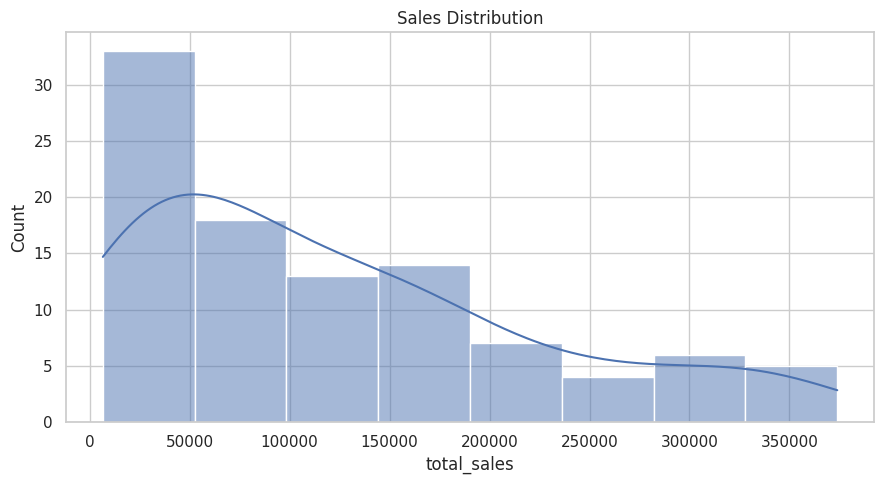

Saved: visualizations/sales_distribution.png

Analysis completed.


In [125]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

DATA_FILE = "sales_data.csv"
OUTPUT_DIR = "visualizations"

def load_data(file_path):
    """Load sales data with basic error handling."""
    try:
        df = pd.read_csv(file_path)
        df.columns = (
            df.columns.str.strip()
            .str.lower()
            .str.replace(" ", "_")
        )
        print("Dataset loaded successfully!")
        print("Dataset shape:", df.shape)
        return df

    except FileNotFoundError:
        print(f"Error: {file_path} not found.")
        return None

    except Exception as error:
        print("Error loading dataset:", error)
        return None


def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    df = load_data(DATA_FILE)

    if df is None:
        return

    print("\nFirst five rows:")
    print(df.head())

    print("\nDataset information:")
    df.info()

    numeric_columns = df.select_dtypes(
        include="number"
    ).columns.tolist()

    if numeric_columns:
        print("\nNumerical summary:")
        print(df[numeric_columns].describe())

        sales_candidates = [
            "total_sales", "sales", "revenue",
            "amount", "price"
        ]

        sales_column = next(
            (
                column for column in sales_candidates
                if column in df.columns
            ),
            None
        )

        if sales_column:
            plt.figure(figsize=(9, 5))
            sns.histplot(
                data=df,
                x=sales_column,
                kde=True
            )
            plt.title("Sales Distribution")
            plt.tight_layout()

            output_path = os.path.join(
                OUTPUT_DIR,
                "sales_distribution.png"
            )
            plt.savefig(output_path, dpi=150)
            plt.show()
            plt.close()

            print("Saved:", output_path)

        else:
            print(
                "No recognized sales column found. "
                "Available columns:",
                df.columns.tolist()
            )

    else:
        print("No numerical columns found.")

    print("\nAnalysis completed.")


if __name__ == "__main__":
    main()

In [126]:
with open("dashboard.py", "w", encoding="utf-8") as file:
    file.write('''import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FILE = "sales_data.csv"
OUTPUT_DIR = "visualizations"

def load_data(file_path):
    try:
        df = pd.read_csv(file_path)
        df.columns = (
            df.columns.str.strip()
            .str.lower()
            .str.replace(" ", "_")
        )
        print("Dataset loaded:", df.shape)
        return df
    except FileNotFoundError:
        print(f"Error: {file_path} not found.")
        return None

def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    df = load_data(DATA_FILE)

    if df is None:
        return

    print(df.head())
    print(df.describe(include="all"))

    candidates = [
        "total_sales", "sales", "revenue",
        "amount", "price"
    ]
    sales_column = next(
        (col for col in candidates if col in df.columns),
        None
    )

    if sales_column:
        plt.figure(figsize=(9, 5))
        sns.histplot(data=df, x=sales_column, kde=True)
        plt.title("Sales Distribution")
        plt.tight_layout()
        plt.savefig(
            os.path.join(OUTPUT_DIR, "sales_distribution.png"),
            dpi=150
        )
        plt.close()
        print("Sales distribution chart saved.")
    else:
        print("Sales column not identified.")
        print("Available columns:", df.columns.tolist())

if __name__ == "__main__":
    main()
''')

print("dashboard.py created successfully!")

dashboard.py created successfully!


In [127]:
import os

required_files = [
    "README.md",
    "dashboard.py",
    "requirements.txt",
    "sales_data.csv"
]

print("FINAL FILE CHECK")
print("=" * 40)

for file_name in required_files:
    if os.path.exists(file_name):
        print(f"✅ Found: {file_name}")
    else:
        print(f"❌ Missing: {file_name}")

print("\nVisualization files:")

if os.path.exists("visualizations"):
    for file_name in sorted(os.listdir("visualizations")):
        print(" -", file_name)
else:
    print("Visualizations folder not found.")

FINAL FILE CHECK
✅ Found: README.md
✅ Found: dashboard.py
✅ Found: requirements.txt
✅ Found: sales_data.csv

Visualization files:
 - category_sales_boxplot.png
 - correlation_heatmap.png
 - correlation_matrix.csv
 - correlation_pairs.csv
 - custom_correlation_heatmap.png
 - interactive_product_sales.html
 - interactive_sales_distribution.html
 - interactive_scatter_plot.html
 - product_dropdown_dashboard.html
 - product_performance.png
 - sales_boxplot.png
 - sales_distribution.png
 - sales_statistical_summary.csv
 - sales_violinplot.png
 - static_dashboard.png


In [128]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import imageio.v2 as imageio
import numpy as np

os.makedirs("visualizations", exist_ok=True)

image_paths = [
    "visualizations/static_dashboard.png",
    "visualizations/sales_by_product.png",
    "visualizations/sales_distribution.png"
]

frames = []

for path in image_paths:
    if os.path.exists(path):
        try:
            image = mpimg.imread(path)

            # Convert image to 8-bit format for GIF
            if image.dtype != np.uint8:
                image = (image * 255).clip(0, 255).astype(np.uint8)

            # Remove alpha channel if present
            if image.ndim == 3 and image.shape[2] == 4:
                image = image[:, :, :3]

            frames.append(image)
            print("Added to demo:", path)

        except Exception as error:
            print("Could not load:", path, error)
    else:
        print("Image not found:", path)

if frames:
    # Make all frames the same size
    from PIL import Image

    pil_frames = [
        Image.fromarray(frame).convert("RGB").resize((800, 500))
        for frame in frames
    ]

    gif_path = "dashboard_demo.gif"

    pil_frames[0].save(
        gif_path,
        save_all=True,
        append_images=pil_frames[1:],
        duration=1200,
        loop=0
    )

    print("\nDashboard demo GIF created:", gif_path)
else:
    print("No dashboard images found.")
    print("Run the earlier visualization cells first.")

Added to demo: visualizations/static_dashboard.png
Image not found: visualizations/sales_by_product.png
Added to demo: visualizations/sales_distribution.png

Dashboard demo GIF created: dashboard_demo.gif


Dashboard demo GIF created successfully!
File size: 78.58 KB


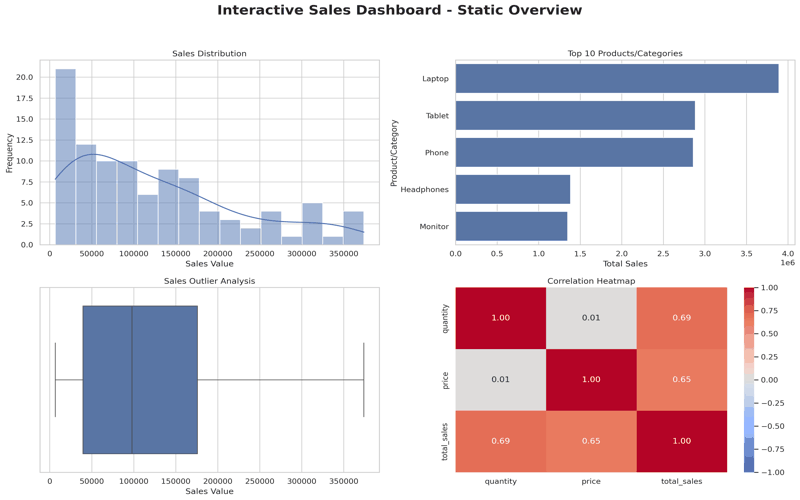

In [129]:
import os
from IPython.display import display, Image

gif_path = "dashboard_demo.gif"

if os.path.exists(gif_path):
    print("Dashboard demo GIF created successfully!")
    print("File size:", round(os.path.getsize(gif_path) / 1024, 2), "KB")
    display(Image(filename=gif_path))
else:
    print("GIF not found. Run Cell 58 again after creating dashboard images.")

In [130]:
import os
import shutil
from google.colab import files

# Visualizations folder path
folder_path = "visualizations"

# Check whether folder exists
if os.path.exists(folder_path):

    # Create ZIP file containing all images and other visualization files
    shutil.make_archive(
        "all_visualizations",
        "zip",
        folder_path
    )

    # Download ZIP file
    files.download("all_visualizations.zip")

    print("All visualizations downloaded successfully!")

else:
    print("Error: visualizations folder not found.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All visualizations downloaded successfully!
